In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from database import engine
import joblib

#so the plots apear inside the notebook
%matplotlib inline 

#models from sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#model evaluations
from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.model_selection import RandomizedSearchCV , GridSearchCV
from sklearn.metrics import confusion_matrix , classification_report
from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score
from sklearn.metrics import RocCurveDisplay


In [34]:
df = pd.read_sql("SELECT * FROM metrics ORDER BY device_id, timestamp" , engine)
print(df.shape)

(112333, 12)


In [35]:
features = ['cpu' , 'memory' , 'temperature' , 'latency' , 'packet_loss' ,'interface_errors','traffic' ]

In [36]:
df.head()

,metrics_id,device_id,timestamp,cpu,memory,temperature,latency,packet_loss,traffic,interface_errors,is_anomaly,failure_soon
0,12,1,2026-09-11 19:48:18.574437,34.431056,46.872459,40.906015,1.873005,0.058565,50.969569,0,False,False
1,25,1,2026-09-11 19:53:18.574437,31.904066,46.707026,40.392506,2.246251,0.000093,47.100787,1,False,False
2,38,1,2026-09-11 19:58:18.574437,31.711784,46.045022,41.180888,2.030630,0.045374,46.843059,1,False,False
3,51,1,2026-09-11 20:03:18.574437,29.658632,44.697165,40.198454,2.331650,0.094563,51.853779,1,False,False
4,64,1,2026-09-11 20:08:18.574437,28.128424,44.160100,40.552234,2.605992,0.175902,50.980078,1,False,False


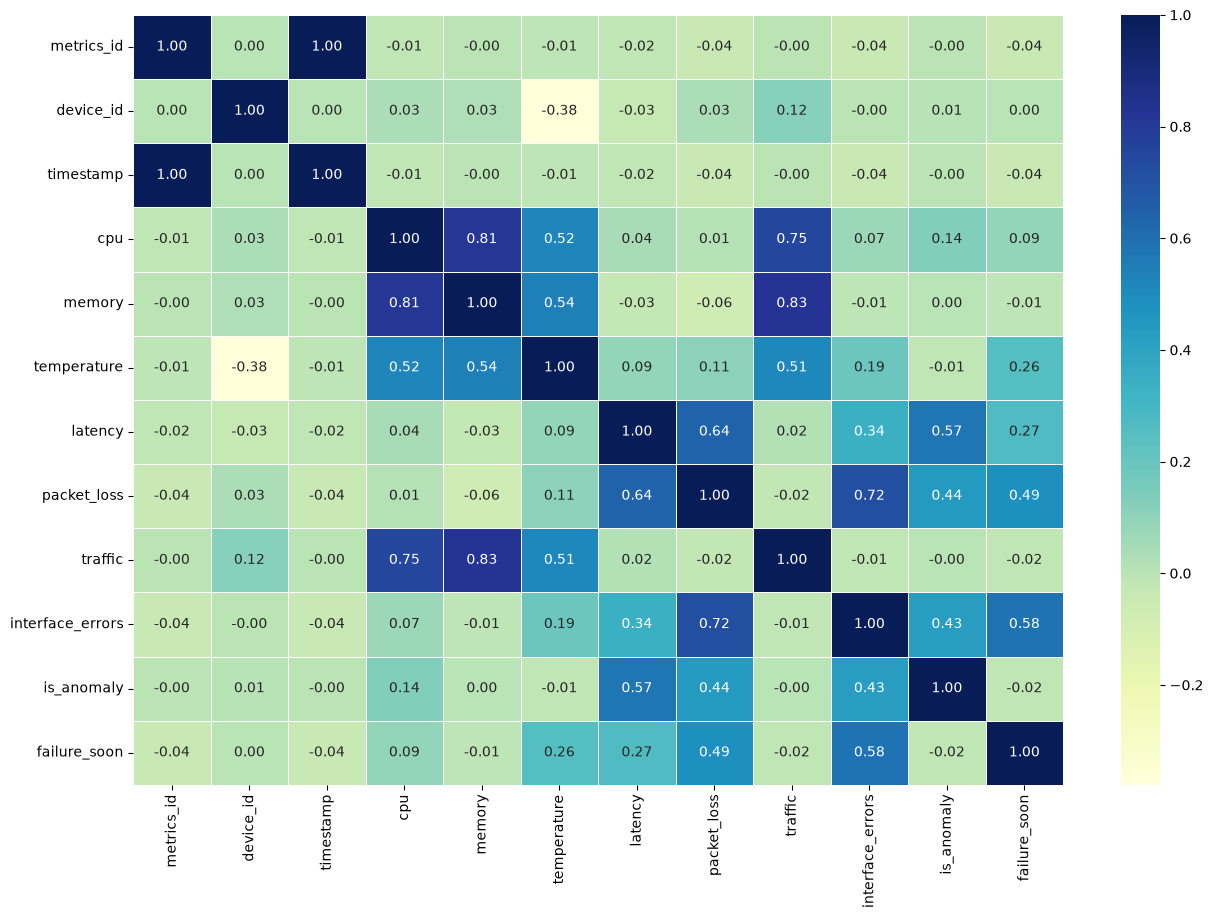

In [37]:
corr_matrix = df.corr()
fig , ax = plt.subplots(figsize = (15 , 10))
sns.heatmap(corr_matrix , 
                    annot = True , 
                    linewidth = 0.5, 
                    fmt = ".2f", 
                    cmap = "YlGnBu");


In [38]:
df.failure_soon.value_counts()

failure_soon
False    110605
True       1728
Name: count, dtype: int64

In [39]:
df.groupby("device_id")["failure_soon"].mean()

device_id
1     0.008332
3     0.016665
4     0.024997
5     0.000000
6     0.041662
7     0.000000
8     0.008332
9     0.024997
10    0.024997
11    0.000000
12    0.024997
13    0.008332
14    0.016665
Name: failure_soon, dtype: float64

In [40]:
pd.crosstab(df.failure_soon , df.is_anomaly)

is_anomaly,False,True
failure_soon,,
False,108774,1831
True,1728,0


In [41]:
df["failure_soon"].describe()

count     112333
unique         2
top        False
freq      110605
Name: failure_soon, dtype: object

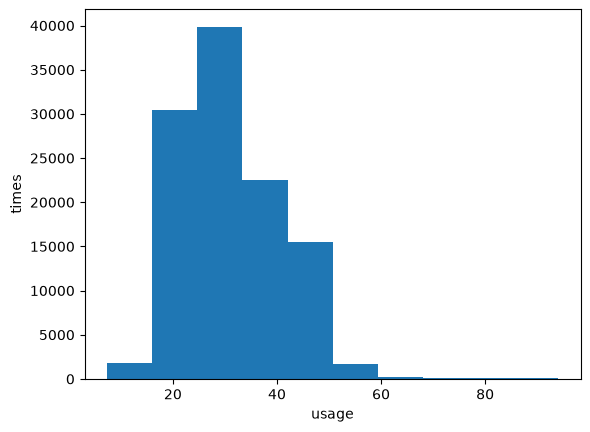

In [42]:
plt.hist(df["cpu"]);
plt.xlabel("usage");
plt.ylabel("times");

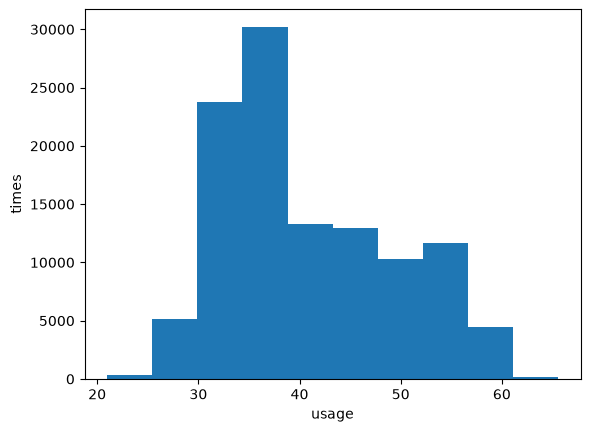

In [43]:
plt.hist(df.memory);
plt.xlabel("usage");
plt.ylabel("times");

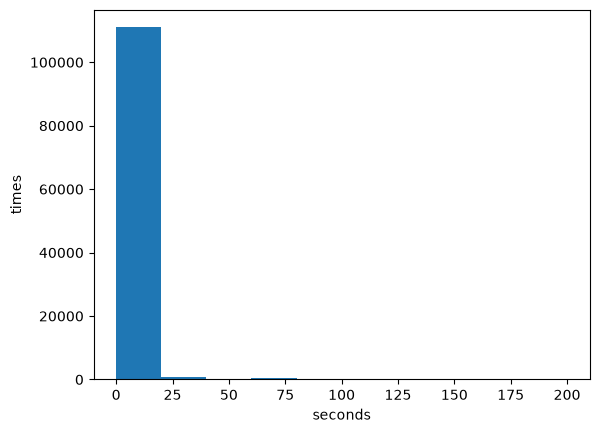

In [44]:
plt.hist(df.latency);
plt.ylabel("times");
plt.xlabel("seconds");


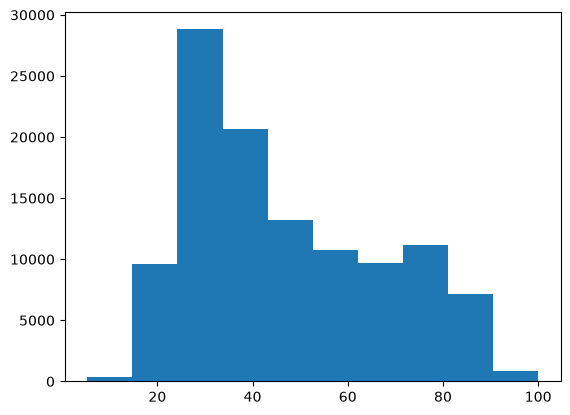

In [45]:
plt.hist(df.traffic);


In [46]:
failure_count = df.groupby("device_id")["failure_soon"].sum().sort_values(ascending=False)
print(failure_count)

device_id
6     360
4     216
12    216
9     216
10    216
3     144
14    144
13     72
1      72
8      72
5       0
7       0
11      0
Name: failure_soon, dtype: int64


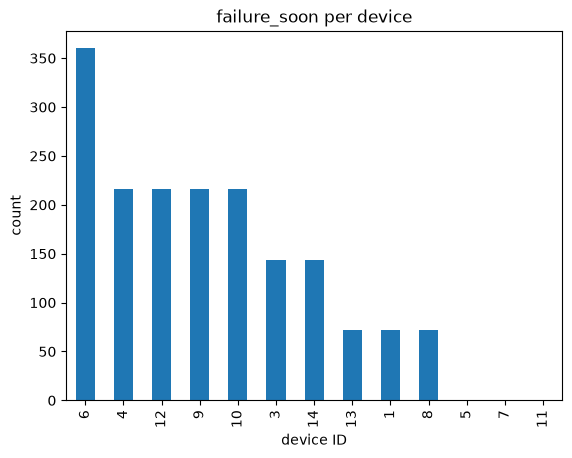

In [47]:
failure_count.plot(kind= "bar" , title = "failure_soon per device");
plt.xlabel("device ID");
plt.ylabel("count");

In [49]:
df = df.sort_values("timestamp")
split = int(len(df) *  0.8)
x = df[features]
y = df.failure_soon
train , test = df.iloc[:split] , df.iloc[split:]
x_train, y_train = train[features] , train["failure_soon"]
x_test , y_test = test[features] , test["failure_soon"]

In [53]:
models = {"Logistic Regression" : LogisticRegression(max_iter=1500 , random_state=42),
          "Random Forest Classifier" : RandomForestClassifier(random_state=42)}
def fit_and_score(models, x_train, x_test, y_train, y_test):
    results = {}
    for name , model in models.items():
        model.fit(x_train , y_train)
        preds = model.predict(x_test)
        results[name] = {
                    "precision": precision_score(y_test, preds, zero_division=0),
                    "recall": recall_score(y_test, preds, zero_division=0),
                    "f1": f1_score(y_test, preds, zero_division=0),
                }
        print(name)
        print(classification_report(y_test , preds , zero_division=0))
    return pd.DataFrame(results).T
        

In [54]:
fit_and_score(models , x_train = x_train , x_test=x_test , y_train= y_train , y_test=y_test)

Logistic Regression
              precision    recall  f1-score   support

       False       0.99      1.00      1.00     22251
        True       0.77      0.44      0.56       216

    accuracy                           0.99     22467
   macro avg       0.88      0.72      0.78     22467
weighted avg       0.99      0.99      0.99     22467

Random Forest Classifier
              precision    recall  f1-score   support

       False       1.00      1.00      1.00     22251
        True       0.91      0.90      0.90       216

    accuracy                           1.00     22467
   macro avg       0.95      0.95      0.95     22467
weighted avg       1.00      1.00      1.00     22467



,precision,recall,f1
Logistic Regression,0.774194,0.444444,0.564706
Random Forest Classifier,0.906977,0.902778,0.904872


In [55]:
final_model = RandomForestClassifier(random_state=42)
final_model.fit(x, y)

joblib.dump({"model": final_model, "features": features}, "failure_prediction_model.joblib")
print("trained and saved the failure prediction model")

trained and saved the failure prediction model
